# Early Signals of Student Dropout: Finding the Line Between Detection and False Alarms

**Tim Xeriland**

<i>Quantitative Research</i> | <i>Predictive Analytics</i>

This analysis examines whether a handful of first-semester academic measures can provide a useful warning of eventual student dropout. Using exploratory statistics and logistic regression, I investigate which patterns distinguish students who graduate from those who leave, how reliably those outcomes can be predicted, and what happens when the threshold for identifying at-risk students is moved. The larger question is not simply whether a model can spot potential dropouts, but whether its predictions are useful enough to inform institutional decisions.

### Dataset

This analysis uses the **Predict Students' Dropout and Academic Success** dataset from the UCI Machine Learning Repository. The dataset contains information on 4,424 higher education students, including demographic, socioeconomic, enrollment, and academic performance variables. The dataset contains 37 variables and no missing values. Student outcomes are classified as **Dropout, Enrolled, or Graduate**.

### Dataset and Running the Notebook

This notebook uses the Predict Students' Dropout and Academic Success dataset from the UCI Machine Learning Repository.

Dataset: https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

This notebook downloads the dataset directly from the UCI Machine Learning Repository. Select Runtime → Run all to reproduce the analysis.

In [22]:
# Bring in the tools and see what kind of student data we're dealing with
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"

import io
import zipfile
import requests

response = requests.get(url)
response.raise_for_status()


with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    df = pd.read_csv(z.open("data.csv"), sep=";")

print(df.shape)


# The dataset was downloaded directly from UCI in the previous cell
df.head()



(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [23]:
# Make the column names a little less annoying before doing anything else
df.columns = (df.columns
              .str.strip()
              .str.lower()
              .str.replace(' ', '_')
              .str.replace('/', '_', regex=False))

# Check the size, data types, and whether anything is missing
print("Dataset shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("\nStudent outcomes:")
print(df['target'].value_counts())

df.info()

Dataset shape: (4424, 37)

Missing values: 0

Student outcomes:
target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   marital_status                                  4424 non-null   int64  
 1   application_mode                                4424 non-null   int64  
 2   application_order                               4424 non-null   int64  
 3   course                                          4424 non-null   int64  
 4   daytime_evening_attendance                      4424 non-null   int64  
 5   previous_qualification                          4424 non-null   int64  
 6   previous_qualification_(grade)                  4424 non-null   float64
 7   nacionality                                    

In [24]:
# See whether the first semester gives us any clues about where students end up
first_semester_outcomes = df.groupby('target')[
    ['curricular_units_1st_sem_(grade)',
     'curricular_units_1st_sem_(approved)']
].mean()

# Hopefully the groups actually look different
print(first_semester_outcomes.round(2))

          curricular_units_1st_sem_(grade)  \
target                                       
Dropout                               7.26   
Enrolled                             11.13   
Graduate                             12.64   

          curricular_units_1st_sem_(approved)  
target                                         
Dropout                                  2.55  
Enrolled                                 4.32  
Graduate                                 6.23  


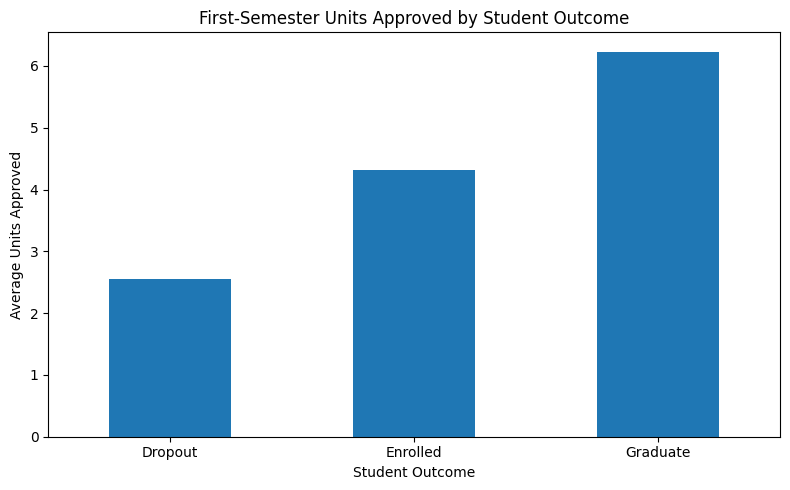

In [25]:
# Turn our three groups into something easier to see than a table
approved_by_outcome = df.groupby('target')['curricular_units_1st_sem_(approved)'].mean()

# Put the difference between the student outcomes on display
approved_by_outcome.plot(kind='bar', figsize=(8, 5))

plt.title('First-Semester Units Approved by Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Average Units Approved')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Preliminary EDA Finding

First-semester academic performance differs substantially across eventual student outcomes. Students who later dropped out completed an average of 2.55 first-semester curricular units, compared with 4.32 for students who remained enrolled and 6.23 for students who graduated. This preliminary finding suggests that early academic performance may provide useful information for identifying students at elevated risk of dropout.

In [26]:

# Let's see how first-semester performance differs among the three student groups.

academic_columns = [
    'curricular_units_1st_sem_(approved)',
    'curricular_units_1st_sem_(grade)',
    'curricular_units_1st_sem_(evaluations)'
]

semester_summary = df.groupby('target')[academic_columns].agg(
    ['mean', 'median', 'std']
)

print(semester_summary.round(2))


         curricular_units_1st_sem_(approved)               \
                                        mean median   std   
target                                                      
Dropout                                 2.55    2.0  2.86   
Enrolled                                4.32    5.0  2.29   
Graduate                                6.23    6.0  2.58   

         curricular_units_1st_sem_(grade)               \
                                     mean median   std   
target                                                   
Dropout                              7.26  10.93  6.03   
Enrolled                            11.13  12.00  3.68   
Graduate                            12.64  13.00  2.70   

         curricular_units_1st_sem_(evaluations)               
                                           mean median   std  
target                                                        
Dropout                                    7.75    8.0  4.92  
Enrolled                        

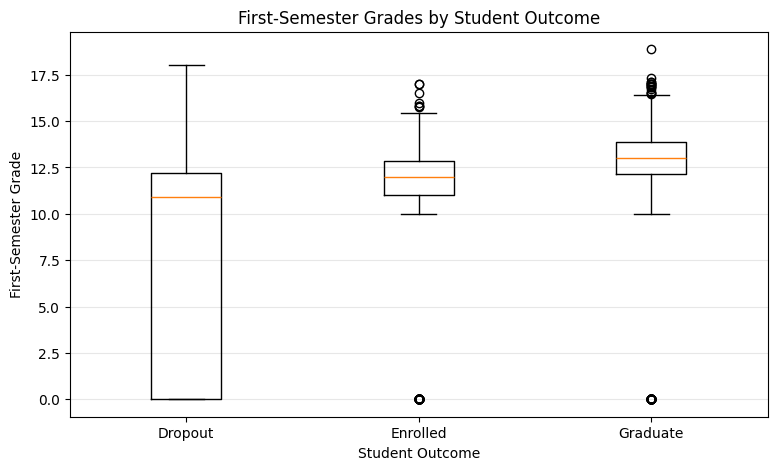

In [27]:

import matplotlib.pyplot as plt

# Let's compare first-semester grades for the three student groups.
grade_col = 'curricular_units_1st_sem_(grade)'
groups = ['Dropout', 'Enrolled', 'Graduate']

# Pull out the grades for each group and leave out missing values.
grade_data = [
    df.loc[df['target'] == group, grade_col].dropna()
    for group in groups
]

# A boxplot should help us see differences that averages might miss.
plt.figure(figsize=(9, 5))
plt.boxplot(grade_data, tick_labels=groups)

# Add labels so it's clear what we're comparing.
plt.title('First-Semester Grades by Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('First-Semester Grade')
plt.grid(axis='y', alpha=0.3)

plt.show()


The boxplot displays considerable variance in first semester grades about student outcome. Students who dropped out had more variation in grades with a large amount of zero scores. Students who graduated generally performed better and were more consistent. The groups overlap, implying that grades after the first semester may not be sufficient to pick out all students susceptible for dropping out.

In [28]:

# Let's take a closer look at students who received a zero for their first-semester grade.
zero_grades = df[df['curricular_units_1st_sem_(grade)'] == 0]

# How many students had zero grades, and what eventually happened to them?
print("Students with zero first-semester grades:", len(zero_grades))
print()
print(zero_grades['target'].value_counts())

# Did these students successfully complete any first-semester units?
print()
print("Units approved among students with zero grades:")
print(zero_grades['curricular_units_1st_sem_(approved)'].value_counts().sort_index())

Students with zero first-semester grades: 718

target
Dropout     570
Graduate     77
Enrolled     71
Name: count, dtype: int64

Units approved among students with zero grades:
curricular_units_1st_sem_(approved)
0    718
Name: count, dtype: int64


In [29]:

# Let's see how dropout rates change as students complete more first-semester units.
units_col = 'curricular_units_1st_sem_(approved)'

dropout_by_units = df.groupby(units_col)['target'].agg(
    total_students='count',
    dropouts=lambda x: (x == 'Dropout').sum()
)

# Calculate the percentage of students who eventually dropped out.
dropout_by_units['dropout_rate'] = (
    dropout_by_units['dropouts'] /
    dropout_by_units['total_students'] * 100
)

print(dropout_by_units.round(1))

                                     total_students  dropouts  dropout_rate
curricular_units_1st_sem_(approved)                                        
0                                               718       570          79.4
1                                               127        93          73.2
2                                               160       112          70.0
3                                               269       139          51.7
4                                               433       158          36.5
5                                               723       145          20.1
6                                              1171       117          10.0
7                                               471        33           7.0
8                                               108        10           9.3
9                                                40         8          20.0
10                                               24         5          20.8
11          

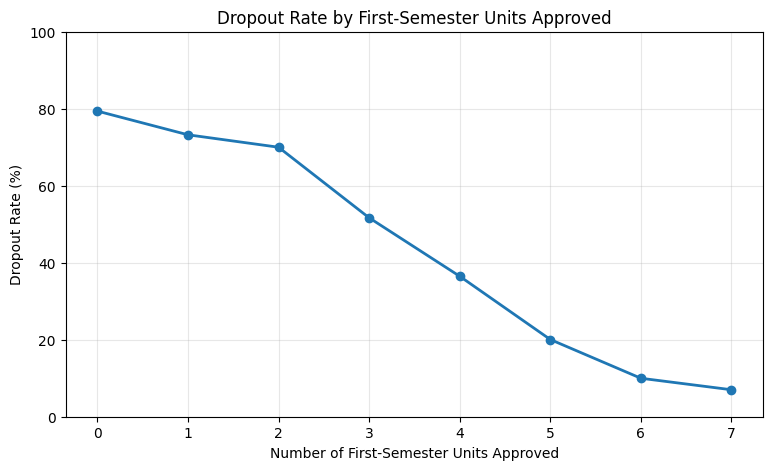

In [30]:

import matplotlib.pyplot as plt

# Let's focus on the number of approved units where most students fall.
plot_data = dropout_by_units.loc[0:7]

plt.figure(figsize=(9, 5))

plt.plot(
    plot_data.index,
    plot_data['dropout_rate'],
    marker='o',
    linewidth=2
)

plt.title('Dropout Rate by First-Semester Units Approved')
plt.xlabel('Number of First-Semester Units Approved')
plt.ylabel('Dropout Rate (%)')
plt.xticks(range(8))
plt.ylim(0, 100)
plt.grid(alpha=0.3)

plt.show()

Comparing academic performance in the first semester to eventually dropping out is stunning. Nearly 80% of students who completed no curricular unit actually ended up dropping out compared to just 10% of students who completed six units. As the number of approved units rises, the probability of dropping out declines in the interval between 2 and 6. This might suggest to us that based on academic performance in the first semester, we can detect students who would actually benefit if someone tried to reach out to them earlier. However, it remains unclear yet how accurately it could track individual students if we considered that based on this information alone, we would have to make decisions which could alter any student's outcomes drastically.

In [31]:

# I suspect some of these variables are telling us basically the same thing.
# Let's see how much overlap there actually is.
academic_columns = [
    'curricular_units_1st_sem_(approved)',
    'curricular_units_1st_sem_(grade)',
    'curricular_units_1st_sem_(evaluations)'
]

# Mainly interested in whether grades and approved units are closely related.
correlations = df[academic_columns].corr()

print(correlations.round(3))

                                        curricular_units_1st_sem_(approved)  \
curricular_units_1st_sem_(approved)                                   1.000   
curricular_units_1st_sem_(grade)                                      0.696   
curricular_units_1st_sem_(evaluations)                                0.522   

                                        curricular_units_1st_sem_(grade)  \
curricular_units_1st_sem_(approved)                                0.696   
curricular_units_1st_sem_(grade)                                   1.000   
curricular_units_1st_sem_(evaluations)                             0.418   

                                        curricular_units_1st_sem_(evaluations)  
curricular_units_1st_sem_(approved)                                      0.522  
curricular_units_1st_sem_(grade)                                         0.418  
curricular_units_1st_sem_(evaluations)                                   1.000  


The relationships were very much what I expected. The strongest relationship was between first-semester grades and approved units (r = .696). This is a fairly substantial correlation, although it doesn't necessarily mean the two measures provide identical information. Evaluations were less strongly correlated with both approved units (r = .522) and grades (r = .418). This suggests that all three measures may contribute useful information when identifying students at risk of dropping out.

In [32]:

# Exclude students who are still enrolled because their final outcome is unknown.
# The model will compare students who graduated with those who dropped out.
model_df = df[df['target'].isin(['Dropout', 'Graduate'])].copy()

# Start with the three academic measures we've been examining.
predictors = [
    'curricular_units_1st_sem_(approved)',
    'curricular_units_1st_sem_(grade)',
    'curricular_units_1st_sem_(evaluations)'
]

X = model_df[predictors]

# Code dropout as 1 and graduation as 0.
y = (model_df['target'] == 'Dropout').astype(int)

print("Students included:", len(model_df))
print()
print("Outcome counts:")
print(y.value_counts())
print()
print("Missing predictor values:")
print(X.isnull().sum())


Students included: 3630

Outcome counts:
target
0    2209
1    1421
Name: count, dtype: int64

Missing predictor values:
curricular_units_1st_sem_(approved)       0
curricular_units_1st_sem_(grade)          0
curricular_units_1st_sem_(evaluations)    0
dtype: int64


In [33]:

from sklearn.model_selection import train_test_split

# Let's hold back 20% of the students to see how well the model
# performs on cases it hasn't already encountered...
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Just checking that the split worked as expected.
print("Training students:", len(X_train))
print("Testing students:", len(X_test))

print()
print("Dropout percentage in training data:", round(y_train.mean() * 100, 1))
print("Dropout percentage in testing data:", round(y_test.mean() * 100, 1))


Training students: 2904
Testing students: 726

Dropout percentage in training data: 39.2
Dropout percentage in testing data: 39.1


In [34]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Time to see whether these three variables can actually predict dropout.
# I'm starting with logistic regression since it's fairly easy to interpret.
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# The model only gets to learn from the training students.
model.fit(X_train, y_train)

# Now let's see how it classifies the students we held back...
y_pred = model.predict(X_test)

print("Model trained successfully.")
print("Predictions generated for", len(y_pred), "students.")

Model trained successfully.
Predictions generated for 726 students.


In [35]:

from sklearn.metrics import accuracy_score, precision_score, recall_score

# Okay, now I'm curious how well this actually worked.
# Accuracy is useful, but I'm more interested in how many dropouts we caught.

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Here's what I got from the first model:")
print()
print("Overall accuracy:", round(accuracy * 100, 1), "%")
print("Precision for predicting dropouts:", round(precision * 100, 1), "%")
print("Percentage of actual dropouts identified:", round(recall * 100, 1), "%")

Here's what I got from the first model:

Overall accuracy: 83.1 %
Precision for predicting dropouts: 80.8 %
Percentage of actual dropouts identified: 74.3 %


In [36]:

from sklearn.metrics import confusion_matrix

# The percentages look pretty good, but I want to see the actual numbers.
# Especially how many students dropped out that we failed to identify.

results = confusion_matrix(y_test, y_pred)

print("Here is how the predictions worked out:")
print()
print("Graduates correctly identified:", results[0][0])
print("Graduates incorrectly flagged as dropouts:", results[0][1])
print("Dropouts we missed:", results[1][0])
print("Dropouts correctly identified:", results[1][1])

Here is how the predictions worked out:

Graduates correctly identified: 392
Graduates incorrectly flagged as dropouts: 50
Dropouts we missed: 73
Dropouts correctly identified: 211


For only having 3 first-semester academic measures as predictors, my initial logistic regression model did better than I expected. The overall accuracy was 83.1% and the model correctly predicted 211 of the 284 students in the test set who eventually dropped out. Nevertheless, it failed to identify 73 of these 284 students and ended up incorrectly labelling 50 graduating students as having dropped out. From the university's perspective, both the students the model failed to identify and those incorrectly flagged are important concerns.

In [37]:

from sklearn.metrics import precision_score, recall_score, accuracy_score

# I'm wondering whether a lower cutoff would help us catch more dropouts.
# The tradeoff, of course, is that we might flag more students unnecessarily.

dropout_probabilities = model.predict_proba(X_test)[:, 1]

new_predictions = (dropout_probabilities >= 0.40).astype(int)

print("Results using a 40% cutoff:")
print()
print("Accuracy:", round(accuracy_score(y_test, new_predictions) * 100, 1), "%")
print("Precision:", round(precision_score(y_test, new_predictions) * 100, 1), "%")
print("Recall:", round(recall_score(y_test, new_predictions) * 100, 1), "%")

Results using a 40% cutoff:

Accuracy: 82.6 %
Precision: 76.7 %
Recall: 79.9 %


In [38]:

# The 40% cutoff helped, but now I'm wondering how low we can go
# before the false alarms start getting ridiculous.
# Let's try a few cutoffs and see what happens.

from sklearn.metrics import confusion_matrix

for cutoff in [0.50, 0.40, 0.30, 0.20]:

    guesses = (dropout_probabilities >= cutoff).astype(int)

    results = confusion_matrix(y_test, guesses)

    missed = results[1][0]
    caught = results[1][1]
    false_alarms = results[0][1]

    print()
    print("Trying", int(cutoff * 100), "percent...")
    print("   Caught:", caught)
    print("   Missed:", missed)
    print("   False alarms:", false_alarms)
    print("   Recall:", round(recall_score(y_test, guesses) * 100, 1), "%")

print()
print("So where do we draw the line?")


Trying 50 percent...
   Caught: 211
   Missed: 73
   False alarms: 50
   Recall: 74.3 %

Trying 40 percent...
   Caught: 227
   Missed: 57
   False alarms: 69
   Recall: 79.9 %

Trying 30 percent...
   Caught: 240
   Missed: 44
   False alarms: 107
   Recall: 84.5 %

Trying 20 percent...
   Caught: 254
   Missed: 30
   False alarms: 159
   Recall: 89.4 %

So where do we draw the line?


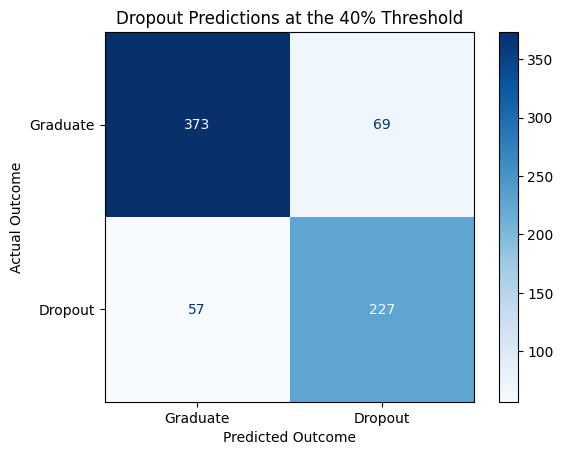

In [39]:

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Let's see what the 40% cutoff actually gets right and wrong.
predictions_40 = (dropout_probabilities >= 0.40).astype(int)

cm_40 = confusion_matrix(y_test, predictions_40)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_40,
    display_labels=['Graduate', 'Dropout']
)

display.plot(cmap='Blues', values_format='d')
plt.title('Dropout Predictions at the 40% Threshold')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.show()

I experimented with some probability levels to determine whether the model was now able to identify more students who would go on to dropout. Lowering the cut-off point from 0.5 to 0.4 resulted in the recall increasing from 74.3% to 79.9%, with false-positives increasing from 50 to 69. Lowering the cutoff identified more dropouts, but also produced more false alarms. The cut-off 0.4 could be considered as making the desirable trade-off between the number of students identified as at risk and the number of students who did not actually end up dropping out but ended up receiving treatment as at risk. The choice of appropriate threshold would eventually boil down to the resources that an institution would want to invest and how expensive it considers it to keep the students identified as at risk happy and preventing an actual drop-out.

I also examined unusual values in the first-semester data, particularly the large number of zero grades. These cases were associated with zero approved units, so I retained them rather than assuming they were data-entry errors. Students with unusually high numbers of approved units were relatively uncommon, making dropout percentages for those groups less stable.

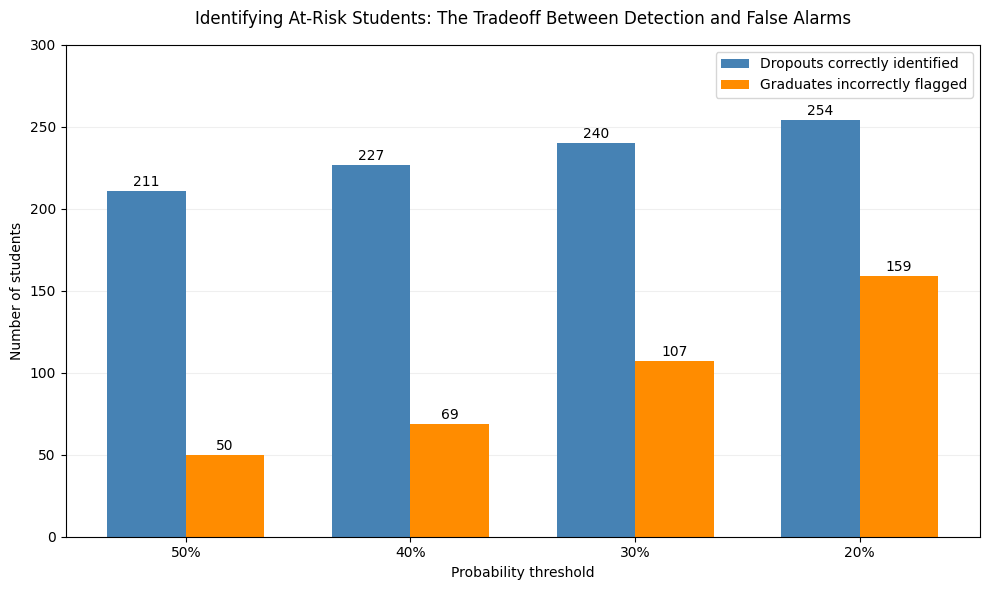

In [40]:

import matplotlib.pyplot as plt
import numpy as np

# I think this is the most interesting part of the analysis.
# Lowering the cutoff catches more dropouts, but at what cost?
# A picture might make the tradeoff easier to explain.


threshold_values = [0.50, 0.40, 0.30, 0.20]
cutoffs = [f'{int(t * 100)}%' for t in threshold_values]

caught = []
false_alarms = []

for threshold in threshold_values:
    predictions = (dropout_probabilities >= threshold).astype(int)
    cm = confusion_matrix(y_test, predictions)

    caught.append(cm[1, 1])
    false_alarms.append(cm[0, 1])


positions = np.arange(4)
bar_width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(positions - bar_width/2, caught, bar_width,
                label='Dropouts correctly identified', color='steelblue')

bars2 = plt.bar(positions + bar_width/2, false_alarms, bar_width,
                label='Graduates incorrectly flagged', color='darkorange')

plt.xticks(positions, cutoffs)
plt.xlabel('Probability threshold')
plt.ylabel('Number of students')
plt.title('Identifying At-Risk Students: The Tradeoff Between Detection and False Alarms',
          fontsize=12, pad=15)

plt.legend()
plt.grid(axis='y', alpha=0.2)
plt.gca().set_axisbelow(True)

for bar in bars1:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             str(int(bar.get_height())), ha='center')

for bar in bars2:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             str(int(bar.get_height())), ha='center')

plt.ylim(0, 300)
plt.tight_layout()
plt.savefig('dropout_threshold_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

The chart illustrates the tradeoff involved in identifying students who may be at risk of dropout. As the required probability decreases, so more and more of the students who do actually drop out are correctly identified. However, increasingly more students who do actually graduate (and therefore not drop out) are flagged as being at risk. To give an instance, the change from a threshold of 40% to 20% would correctly flag 27 additional cases of dropout; but create 90 further false alarms on top. This illustrates why identifying as many potential dropouts as possible is not necessarily the best approach. Universities may have limited advising resources, and incorrectly identifying students as at risk could have unintended consequences. A threshold of 40% seems like a reasonable starting point, but because I selected it after examining the test results, I would need to evaluate it on a separate set of students before using it in practice.

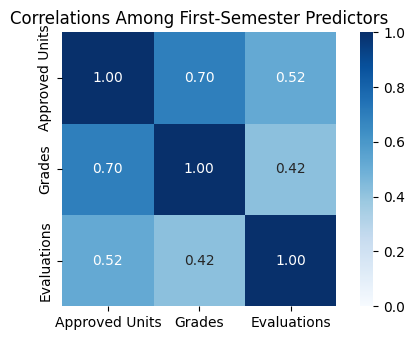

In [41]:


import seaborn as sns

corr = df[[
    'curricular_units_1st_sem_(approved)',
    'curricular_units_1st_sem_(grade)',
    'curricular_units_1st_sem_(evaluations)'
]].corr()

corr.index = ["Approved Units", "Grades", "Evaluations"]
corr.columns = ["Approved Units", "Grades", "Evaluations"]

plt.figure(figsize=(5, 3.5))
sns.heatmap(corr, annot=True, fmt=".2f",
            cmap="Blues", vmin=0, vmax=1,
            square=True)
plt.title("Correlations Among First-Semester Predictors")
plt.tight_layout()
plt.show()


**Concluding Remarks**

The strongest link in the heatmap is between number of units approved and grades (r = .70). Overall, the data indicates that first semester academic performance is useful in identifying students at risk for dropping out. But knowing which students are likely to depart isn’t the same as proving that an intervention will prevent them from leaving. That would take more research.